# Food Marketing: Campaign Response and Customer Segments
## Summary
The supplied cleaned extract contains **2,021 customer-profile rows**. The `Response` indicator is positive for **311 rows (15.39%)**; any recorded campaign acceptance, including `Response`, is positive for **563 rows (27.86%)**.

Profiles with no children at home have a higher observed `Response` rate (**27.87%, n=567**) than profiles with one child (**10.42%, n=1,027**). This is an association in the available extract, not evidence that family composition causes response.

Store purchases account for the largest recorded purchase count (**11,737**), ahead of web (**8,317**) and catalogue (**5,345**). These are purchase counts, not channel revenue or marketing ROI.


## Context and methods
**Goal:** distinguish segment size, observed response rate, and spending before proposing marketing tests.

### Key assumptions
- One row is treated as one customer profile; there is no stable customer ID, so unique-person counts cannot be independently verified.
- The supplied dictionary defines `Response` as acceptance of the last campaign and `AcceptedCmp1`–`AcceptedCmp5` as acceptance of earlier campaigns. Spending fields cover the last two years; exact calendar boundaries are unspecified.
- The supplied case brief describes a simulated customer dataset. The source CSV and cleaned CSV are both available. Exact duplicate removal reproduces all shared fields of the cleaned file; this is a documented working assumption, not proof of duplicate customer identities. Currency, exact observation dates, and redistribution license remain unconfirmed.
- The main analysis uses exact-duplicate removal to match the submitted cleaned file. Sensitivity results retain all source rows, since identical profiles without IDs can represent different people.
- Category labels remain categorical. No regression uses arbitrary marital/education codes.
- Spend and campaign timing are not established; this is descriptive EDA, not a predictive targeting model.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE = '#24577A'


## Data and quality checks


In [2]:
source = ROOT / 'data' / 'cleaned_ufood_marketing.csv'
if not source.exists():
    raise FileNotFoundError(f'Place the supplied cleaned CSV at {source}')
cleaned_reference = pd.read_csv(source)
raw = pd.read_csv(ROOT / 'data' / 'u_food_marketing.csv')
food = raw.drop_duplicates().reset_index(drop=True).copy()
shared = sorted(set(food.columns) & set(cleaned_reference.columns))
pd.testing.assert_frame_equal(food[shared], cleaned_reference[shared].reset_index(drop=True))
sensitivity = pd.DataFrame({
    'population':['all source rows','exact duplicates removed'],
    'rows':[len(raw),len(food)],
    'last_campaign_responses':[int(raw.Response.sum()),int(food.Response.sum())],
    'response_rate':[raw.Response.mean(),food.Response.mean()]})
display(sensitivity)
sensitivity.to_csv(OUT / 'duplicate_sensitivity.csv',index=False)
prior = [f'AcceptedCmp{i}' for i in range(1, 6)]
channels = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
marital = [c for c in food if c.startswith('marital_')]
education = [c for c in food if c.startswith('education_')]
required = prior + channels + ['Response','Age','Kidhome','Teenhome','MntTotal',
    'MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds']
assert not (set(required) - set(food)), 'Required columns are missing'
assert len(food) > 0 and marital and education
assert food[required + marital + education].notna().all().all(), 'Investigate missing inputs'
assert food[prior + ['Response'] + marital + education].isin([0, 1]).all().all()
assert food[marital].sum(axis=1).eq(1).all(), 'Marital indicators must be one-hot'
assert food[education].sum(axis=1).eq(1).all(), 'Education indicators must be one-hot'
assert food[channels + ['Kidhome','Teenhome','MntTotal']].ge(0).all().all()
assert food['Age'].between(0, 120).all()
spend_columns = ['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts']
assert food[spend_columns].sum(axis=1).eq(food['MntTotal']).all(), 'Spend definition changed'
quality = pd.DataFrame({'check':['rows','columns','exact duplicate rows','missing cells'],
                        'value':[len(food),len(food.columns),food.duplicated().sum(),food.isna().sum().sum()]})
display(quality)
quality.to_csv(OUT / 'quality_checks.csv', index=False)


,population,rows,last_campaign_responses,response_rate
0,all source rows,2205,333,0.151
1,exact duplicates removed,2021,311,0.154


,check,value
0,rows,2021
1,columns,39
2,exact duplicate rows,0
3,missing cells,0


### Derive explicit measures
`MntTotal` equals the five food/drink spending fields and excludes `MntGoldProds` in this extract. Currency and period are unconfirmed. Recompute campaign measures from the individual indicators instead of relying on the pre-existing derived fields.


In [3]:
food = food.copy()
food['children_at_home'] = food['Kidhome'] + food['Teenhome']
food['prior_campaign_acceptances'] = food[prior].sum(axis=1)
food['any_campaign_accepted'] = food[prior + ['Response']].max(axis=1)
food['marital_status'] = food[marital].idxmax(axis=1).str.removeprefix('marital_')
food['education_level'] = food[education].idxmax(axis=1).str.removeprefix('education_')
food['age_group'] = pd.cut(food['Age'], [-np.inf,30,40,50,60,70,np.inf],
                           labels=['30 or younger','31–40','41–50','51–60','61–70','71 or older'])
summary = pd.Series({'profile_rows':len(food),'response_count':int(food['Response'].sum()),
    'response_rate':food['Response'].mean(),'any_acceptance_count':int(food['any_campaign_accepted'].sum()),
    'any_acceptance_rate':food['any_campaign_accepted'].mean()})
display(summary.to_frame('value'))
summary.to_csv(OUT / 'summary.csv')


,value
profile_rows,"2,021.000"
response_count,311.000
response_rate,0.154
any_acceptance_count,563.000
any_acceptance_rate,0.279


## Results
### Segment size versus response rate
Every rate below uses the number of profiles **in that segment** as its denominator. Sample sizes are displayed; small groups should not be interpreted as reliable targeting rules.


In [4]:
def segment_table(column):
    result = food.groupby(column, observed=True).agg(
        profiles=('Response','size'), responses=('Response','sum'),
        response_rate=('Response','mean'), any_acceptance_rate=('any_campaign_accepted','mean'),
        median_food_spend=('MntTotal','median'), total_food_spend=('MntTotal','sum'))
    result['profile_share'] = result['profiles'] / len(food)
    assert result['profiles'].sum() == len(food)
    assert result['responses'].sum() == food['Response'].sum()
    return result
age = segment_table('age_group')
children = segment_table('children_at_home')
marital_summary = segment_table('marital_status')
education_summary = segment_table('education_level')
for name, table in [('age',age),('children',children),('marital',marital_summary),('education',education_summary)]:
    table.to_csv(OUT / f'{name}_segments.csv')
display(age)
display(children)


,profiles,responses,response_rate,any_acceptance_rate,median_food_spend,total_food_spend,profile_share
age_group,,,,,,,
30 or younger,55,14,0.255,0.382,670.000,42968,0.027
31–40,327,63,0.193,0.303,121.000,155050,0.162
41–50,669,96,0.143,0.244,224.000,323387,0.331
51–60,455,60,0.132,0.270,394.000,266028,0.225
61–70,421,56,0.133,0.278,503.000,266829,0.208
71 or older,94,22,0.234,0.426,899.000,85156,0.047


,profiles,responses,response_rate,any_acceptance_rate,median_food_spend,total_food_spend,profile_share
children_at_home,,,,,,,
0,567,158,0.279,0.459,"1,114.000",598912,0.281
1,1027,107,0.104,0.217,265.000,444416,0.508
2,382,44,0.115,0.196,84.000,85288,0.189
3,45,2,0.044,0.111,62.000,10802,0.022


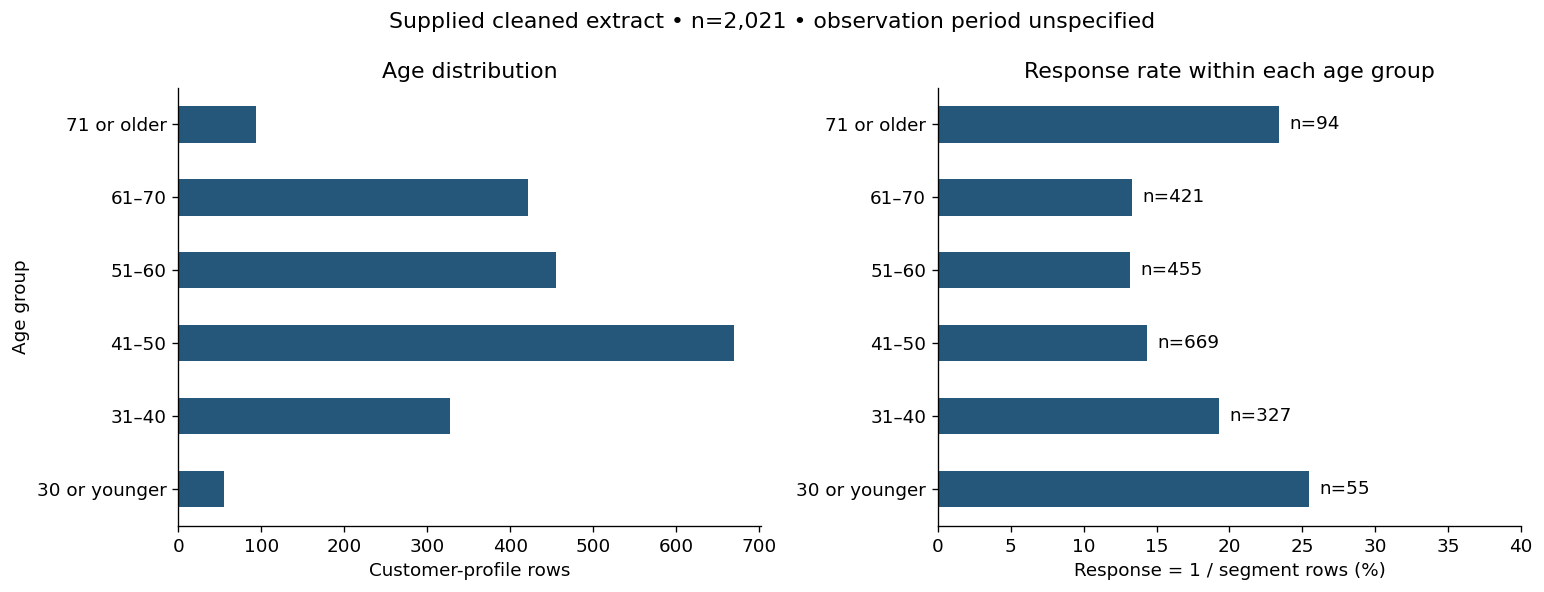

In [5]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
age['profiles'].plot.barh(ax=axes[0], color=BLUE)
axes[0].set(title='Age distribution', xlabel='Customer-profile rows', ylabel='Age group')
(age['response_rate']*100).plot.barh(ax=axes[1], color=BLUE)
axes[1].set(title='Response rate within each age group', xlabel='Response = 1 / segment rows (%)', ylabel='')
axes[1].set_xlim(0, max(40,age['response_rate'].max()*130))
for i, (_,row) in enumerate(age.iterrows()):
    axes[1].text(row['response_rate']*100+0.7,i,f"n={int(row['profiles']):,}",va='center')
fig.suptitle('Supplied cleaned extract • n=2,021 • observation period unspecified')
fig.tight_layout(); fig.savefig(OUT/'age_response.png',dpi=160,bbox_inches='tight'); plt.show()


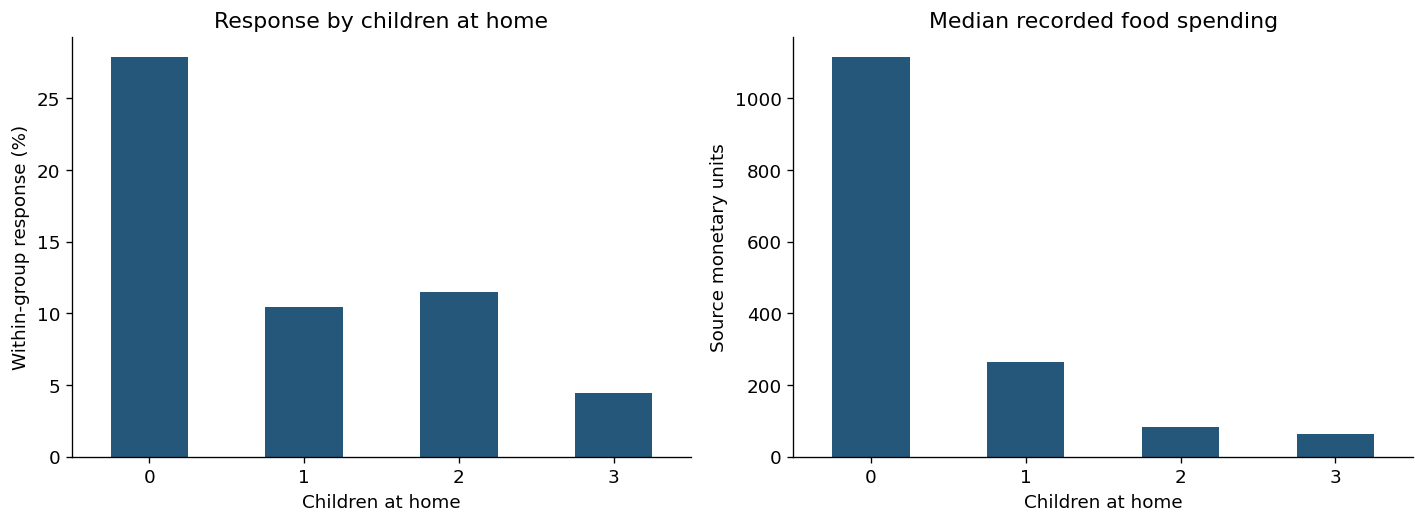

In [6]:
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
(children['response_rate']*100).plot.bar(ax=axes[0],color=BLUE,rot=0)
axes[0].set(title='Response by children at home',xlabel='Children at home',ylabel='Within-group response (%)')
children['median_food_spend'].plot.bar(ax=axes[1],color=BLUE,rot=0)
axes[1].set(title='Median recorded food spending',xlabel='Children at home',ylabel='Source monetary units')
fig.tight_layout(); fig.savefig(OUT/'children_response_spend.png',dpi=160,bbox_inches='tight'); plt.show()


The difference between groups suggests a hypothesis for a controlled test. It does not identify incremental campaign lift. Income, age, historical engagement, and the cleaning process may explain part of the association.

### Education and marital status
Use group summaries rather than treating category labels as a numeric scale. Different group totals can result from different group sizes.


In [7]:
display(marital_summary)
display(education_summary)


,profiles,responses,response_rate,any_acceptance_rate,median_food_spend,total_food_spend,profile_share
marital_status,,,,,,,
Divorced,214,43,0.201,0.294,349.000,120959,0.106
Married,785,92,0.117,0.257,345.000,431445,0.388
Single,443,103,0.233,0.321,303.000,251580,0.219
Together,509,55,0.108,0.257,313.000,286887,0.252
Widow,70,18,0.257,0.357,598.500,48547,0.035


,profiles,responses,response_rate,any_acceptance_rate,median_food_spend,total_food_spend,profile_share
education_level,,,,,,,
2n Cycle,183,22,0.120,0.230,180.000,83004,0.091
Basic,49,2,0.041,0.122,40.000,2997,0.024
Graduation,1015,142,0.140,0.273,350.000,582133,0.502
Master,335,53,0.158,0.284,339.000,194042,0.166
PhD,439,92,0.210,0.326,446.000,277242,0.217


### Purchase channels


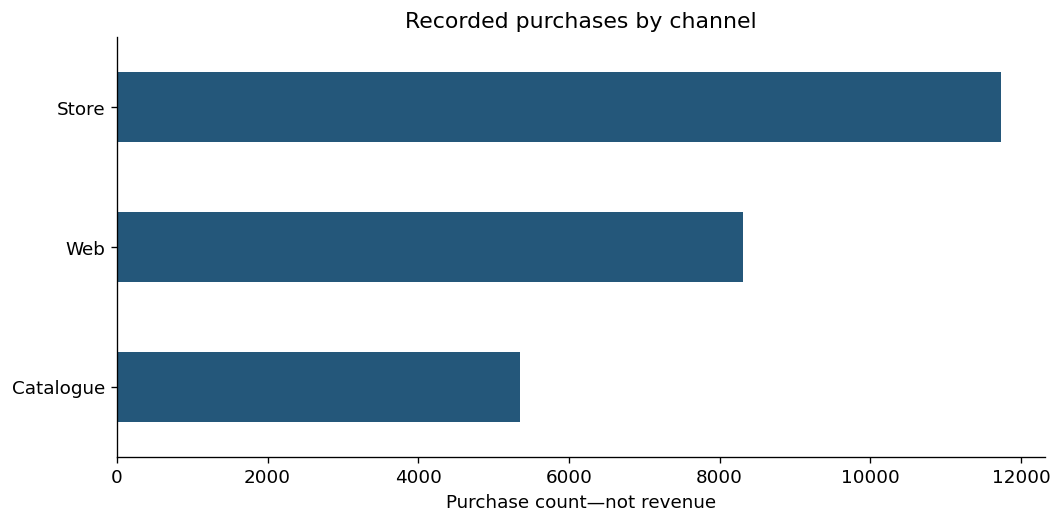

In [8]:
channel_counts = food[channels].sum().rename(index={
    'NumWebPurchases':'Web','NumCatalogPurchases':'Catalogue','NumStorePurchases':'Store'})
channel_counts.to_csv(OUT/'channel_purchase_counts.csv',header=['recorded_purchases'])
fig,ax=plt.subplots(figsize=(9,4.5))
channel_counts.sort_values().plot.barh(ax=ax,color=BLUE)
ax.set(title='Recorded purchases by channel',xlabel='Purchase count—not revenue',ylabel='')
fig.tight_layout();fig.savefig(OUT/'channel_purchases.png',dpi=160,bbox_inches='tight');plt.show()


## Behavioral segmentation
Segments use recorded spending and recency, not demographics or the target response. Higher spending means at least the sample median; recent means last purchase within 30 days. These are transparent exploratory cutoffs, not optimized rules. Spending covers two years; its timing relative to the campaign is unknown, so segments support descriptive review rather than leakage-free prediction.


Spending cutoff: 343 source monetary units; recency cutoff: 30 days


,profiles,responses,response_rate,any_acceptance_rate,median_food_spend,total_food_spend,profile_share
behavior_segment,,,,,,,
Higher spend / less recent,683,112,0.164,0.375,959.000,706796,0.338
Higher spend / recent,330,100,0.303,0.464,964.000,335960,0.163
Lower spend / less recent,683,38,0.056,0.116,54.000,64604,0.338
Lower spend / recent,325,61,0.188,0.231,59.000,32058,0.161


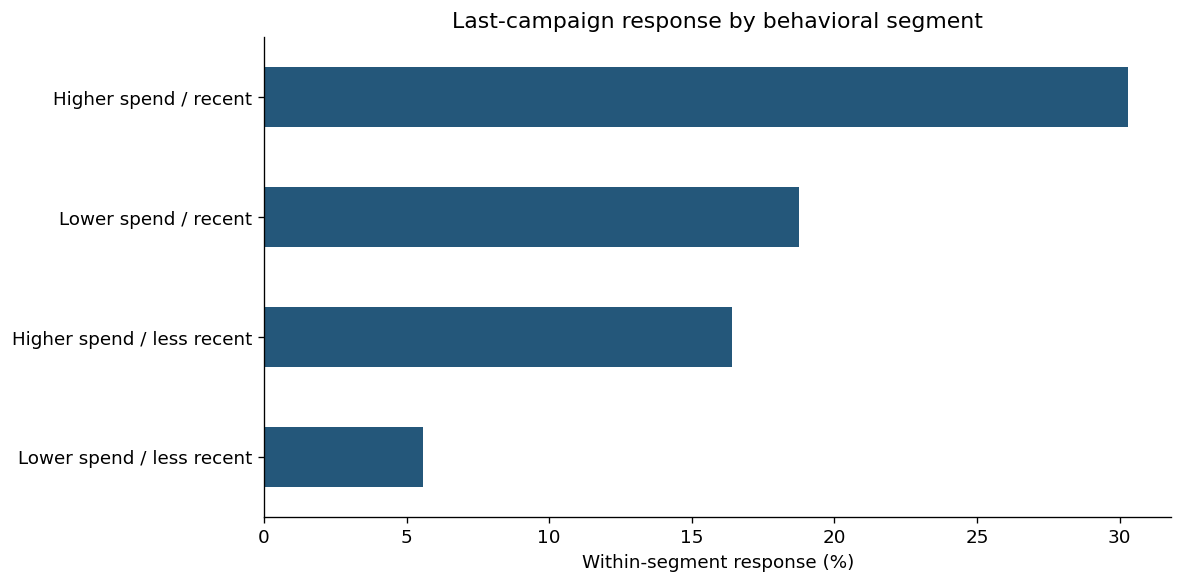

In [9]:
spend_cutoff = food['MntTotal'].median()
food['behavior_segment'] = np.select([
    food['MntTotal'].ge(spend_cutoff) & food['Recency'].le(30),
    food['MntTotal'].ge(spend_cutoff) & food['Recency'].gt(30),
    food['MntTotal'].lt(spend_cutoff) & food['Recency'].le(30)],
    ['Higher spend / recent','Higher spend / less recent','Lower spend / recent'],
    default='Lower spend / less recent')
behavior = segment_table('behavior_segment')
print(f'Spending cutoff: {spend_cutoff:,.0f} source monetary units; recency cutoff: 30 days')
display(behavior)
behavior.to_csv(OUT/'behavior_segments.csv')
fig,ax=plt.subplots(figsize=(10,5))
(behavior['response_rate']*100).sort_values().plot.barh(ax=ax,color=BLUE)
ax.set(title='Last-campaign response by behavioral segment',xlabel='Within-segment response (%)',ylabel='')
fig.tight_layout();fig.savefig(OUT/'behavior_segments.png',dpi=160,bbox_inches='tight');plt.show()


## Takeaways
- Keep customer composition and within-segment response rates separate in reporting.
- Investigate the higher observed response among profiles with no children, then test an offer with randomized treatment/control groups before expanding targeting.
- Store has the largest recorded purchase count. No channel advertising budget split is justified without campaign costs, margin, attribution, and incremental response evidence.
- Do not use current spending or campaign-derived fields to predict a response without establishing that the predictors precede the outcome.
- Preserve source provenance and cleaning decisions before describing these results as representative of all customers.

## Provenance and contribution
Based on Sharan Kumar Rathod's submitted course-practice notebook, identified by the author as Alex the Analyst course work. The original lesson and dataset URLs remain to be supplied. This revision corrects metrics, validates inputs, separates outcomes, and adds reproducible outputs. No original data collection or measured client impact is claimed.


## Source reconciliation
The 2,205-row source contains 184 exact duplicates. Removing those reproduces the supplied cleaned file on every shared column. Last-campaign response changes from 333/2,205 (15.10%) to 311/2,021 (15.39%). There is no customer ID, so the deduplicated population remains an assumption. `Z_CostContact` and `Z_Revenue` are constants and lack sufficient definitions in the supplied dictionary; they are not used to claim ROI. The case brief requests cause/effect discussion, but observational records alone do not establish causation.
